Referências: https://www.geeksforgeeks.org/machine-learning/xgboost-parameters/


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

df = pd.read_csv("dataset.csv")

In [2]:
# Cross Validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

In [3]:
X = df.drop(columns="victory")
y = df.iloc[:, -1]

#sem muitos teste para ajustar o modelo seu primeiro resultado (0.86) já foi melhor que o random forest com ajustes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = XGBClassifier(random_state=42)

scores = cross_val_score(model, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score para cada pedaço: {[round(score, 4) for score in scores]}")
print(f"Média de resultado: {average:.2f}")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Score para cada pedaço: [np.float64(0.9453), np.float64(0.9447), np.float64(0.9327), np.float64(0.9423), np.float64(0.935)]
Média de resultado: 0.94
Accuracy: 0.942


In [4]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Lose", "Win"]))

              precision    recall  f1-score   support

        Lose       0.94      0.94      0.94      1460
         Win       0.94      0.94      0.94      1540

    accuracy                           0.94      3000
   macro avg       0.94      0.94      0.94      3000
weighted avg       0.94      0.94      0.94      3000



In [5]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Hiperparâmetros vencedores do GridSearch_XGBClassifier.ipynb (F1 = 0.9544)
modelo_ajustado = XGBClassifier(learning_rate=0.1,
                                n_estimators=500,
                                max_depth=3,
                                subsample=0.5,
                                colsample_bytree=1,
                                reg_alpha=0,
                                reg_lambda=1,
                                random_state=42)

scores = cross_val_score(modelo_ajustado, X, y, cv=kf, scoring="accuracy")
average = np.mean(scores)

print(f"Score for each fold: {[round(score, 4) for score in scores]}")
print(f"Average accuracy across {k} folds: {average:.2f}")

modelo_ajustado.fit(X_treino, y_treino)
y_predc = modelo_ajustado.predict(X_teste)

accuracy = accuracy_score(y_teste, y_predc)
print("Accuracy:", accuracy)

Score for each fold: [np.float64(0.9523), np.float64(0.9527), np.float64(0.9543), np.float64(0.9587), np.float64(0.952)]
Average accuracy across 5 folds: 0.95
Accuracy: 0.9573333333333334


In [6]:
from sklearn.metrics import classification_report

print(classification_report(y_teste, y_predc, target_names=["Lose", "Win"]))

              precision    recall  f1-score   support

        Lose       0.96      0.95      0.96      1460
         Win       0.96      0.96      0.96      1540

    accuracy                           0.96      3000
   macro avg       0.96      0.96      0.96      3000
weighted avg       0.96      0.96      0.96      3000



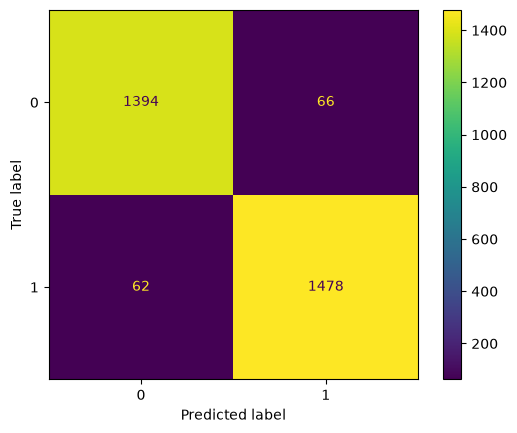

In [7]:
# Cria a matriz de confusão
cm = confusion_matrix(y_teste, y_predc)

ConfusionMatrixDisplay(confusion_matrix=cm).plot();

In [8]:
# Calcula a probabilidade de vitoria
probabilities = modelo_ajustado.predict_proba(X_teste)
indice_vitoria = list(modelo_ajustado.classes_).index(1)

# Extraindo a probabilidade de vitória em porcentagem
chances_vitoria = probabilities[:, indice_vitoria] * 100

# Exibindo os resultados
resultados = pd.DataFrame({
    "Resultado real": y_teste.values,
    "Chance de vitória (%)": chances_vitoria,
    "Previsão do modelo": modelo_ajustado.predict(X_teste)
})

print(resultados)

      Resultado real  Chance de vitória (%)  Previsão do modelo
0                  1              95.300194                   1
1                  0               5.246257                   0
2                  0               0.359645                   0
3                  0               0.401279                   0
4                  0               0.141256                   0
...              ...                    ...                 ...
2995               1              85.759354                   1
2996               1              82.604103                   1
2997               0               0.000059                   0
2998               0              12.358978                   0
2999               0               2.833355                   0

[3000 rows x 3 columns]


In [ ]:
import joblib

# salva o modelo treinado + a ordem das colunas usadas no treino
joblib.dump(
    {"modelo": modelo_ajustado, "features": list(X.columns)},
    "modelo_xgb.joblib"
)
print("Modelo salvo em modelo_xgb.joblib")

Modelo salvo em modelo_xgb.joblib
